In [1]:
import sys
import os
import scipy.ndimage as nd
import scipy.io as io
import numpy as np
import matplotlib.pyplot as plt
import skimage.measure as sk
from utils import utils
plt.style.use('ggplot')

ImportError: cannot import name '_accumulate' from 'torch._utils' (C:\Users\rafae\Dev\vasijas\.venv\Lib\site-packages\torch\_utils.py)

In [2]:
from torch.autograd import Variable
from torchvision import datasets
from torchvision import transforms as tfs
from torch.utils import data

import torch
import PIL.ImageOps

In [3]:
available_device = "cuda" if torch.cuda.is_available() else "cpu"

#### Load dataset

In [4]:
transformations = [tfs.RandomHorizontalFlip(p=0.7), 
                   tfs.RandomAffine(0, scale=(0.7, 1.), fillcolor=(255, 255, 255)), 
                   tfs.RandomRotation((0,360), fill=(255,255, 255)), 
                   tfs.Resize((128, 128))]

imagenet_data = datasets.ImageFolder('data/perfiles_CATA/png_clasificados/',
                                     transform=tfs.Compose(transformations))

data_loader = data.DataLoader(imagenet_data, batch_size=4, shuffle=True)

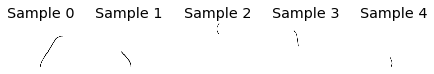

In [5]:
fig = plt.figure()

for i in range(len(imagenet_data)):
    sample = imagenet_data[i + 10]
    #print(sample)
    ax = plt.subplot(1, 5, i + 1)
    plt.tight_layout()
    plt.imshow(np.asarray(sample[0]), cmap=plt.cm.gray_r)
    ax.set_title('Sample {}'.format(i))
    ax.axis('off')

    if i == 4:
        plt.show()
        break

#### Process type of vessels for classification

In [6]:
df = utils.create_df_from_files(path='data/perfiles_CATA/clases/')

#### Build and train classifier

In [7]:
transformations.append(tfs.ToTensor())

In [8]:
imagenet_data = datasets.ImageFolder('data/perfiles_CATA/png_clasificados/',
                                     transform=tfs.Compose(transformations))


In [9]:
splits_len = round(len(imagenet_data.samples)*0.2), round(len(imagenet_data.samples)*0.1), round(len(imagenet_data.samples)*0.7)

In [10]:
splits_len

(999, 500, 3498)

In [11]:
len(imagenet_data.imgs)

4997

In [12]:
sum(splits_len)

4997

#### Random split

In [13]:
splits = utils.random_split(imagenet_data, splits_len)

In [14]:
splits

In [15]:
splits[0].indices

tensor([3620, 2632, 4302, 4053,  362, 3256, 4019, 3392, 3772, 1436,  309, 2278,
        1343,  408, 4067, 4948, 2616, 1662, 1851, 2508,   92, 3686, 3453, 1940,
        3087, 1331, 3830, 2796, 4531, 4729, 4550, 1538, 1665, 2873, 1510, 4599,
        2930, 4577, 2126,  421, 1346, 2906, 2445, 3634,  597, 4090, 1544, 3783,
        3041, 2287, 1172, 2157, 3198, 1800, 4054, 4649, 3425, 1054, 2053, 3200,
        2800, 1782, 2207, 3904, 1625, 3230, 2093, 1315,  199,  957, 3249, 3120,
        4335, 4987, 2830,  502, 4869,   25, 1176, 3241, 1424, 3401, 2827, 3997,
        1878, 3344, 3250,    6, 4084, 2051, 4788, 3483,  496, 3544, 1907,  403,
        4254, 1875,   95, 4323, 2554, 3062, 3606, 4803, 3021, 2797, 4307, 4330,
         708, 1439, 3817, 2620, 1700, 3422, 4286, 3517,  358, 2212,   69, 2829,
        1179, 4505,  723, 4834, 3788, 4983, 3071, 2663, 2968, 3580, 2886,  725,
        4488, 2934, 2874,  226,  971, 2172, 3558, 1082, 1517, 4633,   81, 4153,
        3129, 3707, 1562,  654,  184,  1

In [16]:
import pickle

In [17]:
filehandler = open("data_pickle/test.pickle", 'wb') 
pickle.dump(splits[0].indices, filehandler)
filehandler = open("data_pickle/train.pickle", 'wb') 
pickle.dump(splits[2].indices, filehandler)
filehandler = open("data_pickle/valid.pickle", 'wb') 
pickle.dump(splits[1].indices, filehandler)

In [18]:
#file_pi2 = open('data_pickle/test.pickle', 'rb') 
#splits[0].indices = pickle.load(file_pi2)
#file_pi2 = open('data_pickle/train.pickle', 'rb') 
#splits[2].indices = pickle.load(file_pi2)
#file_pi2 = open('data_pickle/valid.pickle', 'rb') 
#splits[1].indices = pickle.load(file_pi2)

In [19]:
train_loader = data.DataLoader(splits[2], batch_size=32, shuffle=True)
val_loader = data.DataLoader(splits[1], batch_size=32, shuffle=True)
test_loader = data.DataLoader(splits[0], batch_size=32, shuffle=True)

In [20]:
import torch.optim as optim
from torch import nn
from models.classifierResnet import _C
import visdom
from ignite.engine import Events, create_supervised_trainer, create_supervised_evaluator
from ignite.metrics import TopKCategoricalAccuracy, Loss
from ignite.handlers import ModelCheckpoint
import torch.nn.functional as F

In [ ]:
C =_C(input_h_w=128)
C = C.to(available_device)
criterion = nn.CrossEntropyLoss().to(available_device)
#lr=0.0002
C_optimizer = optim.Adam(C.parameters(), lr=0.00001, betas=(0.5, 0.999))

log_interval = 10
trainer = create_supervised_trainer(C, C_optimizer, F.cross_entropy, device=available_device)

evaluator = create_supervised_evaluator(C, metrics={'accuracy': TopKCategoricalAccuracy(),
                                                     'ce_ll': Loss(F.cross_entropy)},
                                           device=available_device)


@trainer.on(Events.EPOCH_COMPLETED)
def log_training_results(engine):
    evaluator.run(train_loader)
    metrics = evaluator.state.metrics
    avg_accuracy = metrics['accuracy']
    avg_nll = metrics['ce_ll']
    print("Training Results - Epoch: {}  Avg accuracy: {:.2f} Avg loss: {:.2f}"
          .format(engine.state.epoch, avg_accuracy, avg_nll))

@trainer.on(Events.EPOCH_COMPLETED)
def log_validation_results(engine):
    evaluator.run(val_loader)
    metrics = evaluator.state.metrics
    avg_accuracy = metrics['accuracy']
    avg_nll = metrics['ce_ll']
    print("Validation Results - Epoch: {}  Avg accuracy: {:.2f} Avg loss: {:.2f}"
          .format(engine.state.epoch, avg_accuracy, avg_nll))

trainer.run(train_loader, max_epochs=25)

Training Results - Epoch: 1  Avg accuracy: 0.85 Avg loss: 1.59
Validation Results - Epoch: 1  Avg accuracy: 0.84 Avg loss: 1.70
Training Results - Epoch: 2  Avg accuracy: 0.90 Avg loss: 1.36
Validation Results - Epoch: 2  Avg accuracy: 0.90 Avg loss: 1.42


In [ ]:
from torchsummary import summary
if available_device == "cuda":
    summary(C, (3, 128, 128))

### Confusion matrix and classification report

In [ ]:
import torchnet

#confusion_window = utils.create_plot_window(vis, 'True Labels', 'Predicted', 'Confusion Matrix')

confusion_matrix = torchnet.meter.ConfusionMeter(11, normalized=True)
for ii, data_ in enumerate(test_loader):
    input_, label = data_
    val_input = Variable(input_).to(available_device)
    val_label = Variable(label.type(torch.LongTensor)).to(available_device)
    score = C(val_input)
    confusion_matrix.add(score.data.squeeze(), label.type(torch.LongTensor))
    
np.set_printoptions(precision=3)
print(confusion_matrix.value())
print(confusion_matrix.conf)
#vis.heatmap(confusion_matrix.value(), win=confusion_window)

In [ ]:
from sklearn import metrics

def iterations_test(C, test_loader):
    y_real = list()
    y_pred = list()

    for ii, data_ in enumerate(test_loader):
        input_, label = data_
        val_input = Variable(input_).to(available_device)
        val_label = Variable(label.type(torch.LongTensor)).to(available_device)
        score = C(val_input)
        _, y_pred_batch = torch.max(score, 1)
        y_pred_batch = y_pred_batch.cpu().squeeze().numpy()
        y_real_batch = val_label.cpu().data.squeeze().numpy()
        y_real.append(y_real_batch.tolist())
        y_pred.append(y_pred_batch.tolist())

    y_real = [item for batch in y_real for item in batch]
    y_pred = [item for batch in y_pred for item in batch]
    
    return y_real, y_pred

In [ ]:
y_real, y_pred = iterations_test(C, test_loader)
print(metrics.classification_report(np.array(y_pred), np.array(y_real)))

In [ ]:
from sklearn.metrics import f1_score 
from sklearn.metrics import recall_score 
from sklearn.metrics import precision_score 

In [ ]:
print("Custom CNN")
print("Precision: ",precision_score(y_real, y_pred, average='macro'))
print("F1_score: ",f1_score(y_real, y_pred, average='macro'))
print("Recall: ",recall_score(y_real, y_pred, average='macro'))

In [ ]:
avg_acc = list()
for i in range(5):
    y_real, y_pred = iterations_test(C, test_loader)
    avg_acc.append(metrics.accuracy_score(np.array(y_pred), np.array(y_real)))
print(np.mean(avg_acc), avg_acc)

In [ ]:
torch.save(C.state_dict(), 'models/checkpoint_resnet_frag_150.pkl')